# Notebook 01: Splits, Monte Carlo Bias–Variance Decomposition & Learning Curves

In this notebook, we explore the theoretical foundations of model selection and generalization error:

1. **Data Splitting & Stratified K-Fold CV:** Why random splitting leaks class balance in imbalanced datasets and how stratified cross-validation preserves label distributions across folds.
2. **Monte Carlo Verification of the Bias–Variance Decomposition:** Proving empirically across 50 independent training sets that:
   $$\mathbb{E}[(y - \hat{f}(x))^2] = \text{Bias}^2(\hat{f}(x)) + \text{Var}(\hat{f}(x)) + \sigma_\epsilon^2$$
3. **Taming High Variance with $L_2$ Regularization:** Watching degree-12 polynomial spaghetti collapse into stable predictions as $\lambda$ increases.
4. **Learning Curves ($m$-sweep):** Diagnosing high bias (underfitting plateaus) vs. high variance (wide generalization gaps).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_DIR = Path.cwd()
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.diagnostics_engine import (
    LinearRegressionScratch,
    PolynomialFeaturesScratch,
    StratifiedKFoldScratch,
    bias_variance_monte_carlo,
)
from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    save_fig,
)

apply_github_dark_style()
np.set_printoptions(precision=4, suppress=True)

## 1. Monte Carlo Bias–Variance Simulation Across 50 Independent Datasets

We generate $50$ independent synthetic training datasets $\mathcal{D}_1, \dots, \mathcal{D}_{50}$ of size $m=26$
from a non-linear true generating function $f(x) = \sin(1.7 x) + 0.35 x^2 - 0.2 x$ corrupted by Gaussian noise
$\epsilon \sim \mathcal{N}(0, 0.42^2)$.

We fit:
- Degree 1 (Underfitting / High Bias): $\hat{f}(x) = w_1 x + b$
- Degree 12 (Overfitting / High Variance): Unregularized polynomial fitting random noise
- Degree 12 + $L_2$ Regularization: Ridge regression with $\lambda = 1.5$

In [2]:
def f_true(x: np.ndarray) -> np.ndarray:
    return np.sin(1.7 * x) + 0.35 * (x ** 2) - 0.2 * x

def make_poly_predictor(degree: int, l2_lambda: float = 0.0):
    def _fit_predict(X_tr: np.ndarray, y_tr: np.ndarray, X_ev: np.ndarray) -> np.ndarray:
        poly = PolynomialFeaturesScratch(degree=degree, include_bias=False)
        # Center features
        X_p_tr = poly.fit_transform(X_tr)
        X_p_ev = poly.transform(X_ev)
        mu = np.mean(X_p_tr, axis=0, keepdims=True)
        std = np.std(X_p_tr, axis=0, keepdims=True)
        std = np.where(std < 1e-12, 1.0, std)
        Phi_tr = (X_p_tr - mu) / std
        Phi_ev = (X_p_ev - mu) / std

        m_tr, n_feat = Phi_tr.shape
        if l2_lambda > 0.0:
            Phi_c = Phi_tr - np.mean(Phi_tr, axis=0, keepdims=True)
            y_c = y_tr.ravel() - np.mean(y_tr)
            w = np.linalg.solve(Phi_c.T @ Phi_c + l2_lambda * np.eye(n_feat), Phi_c.T @ y_c)
            b = float(np.mean(y_tr) - np.mean(Phi_tr, axis=0) @ w)
            return Phi_ev @ w + b
        else:
            aug = np.hstack([np.ones((m_tr, 1)), Phi_tr])
            th = np.linalg.pinv(aug) @ y_tr.reshape(-1, 1)
            return (Phi_ev @ th[1:] + th[0, 0]).ravel()

    return _fit_predict

x_eval = np.linspace(-1.85, 1.85, 160)
noise_sigma = 0.42

mc_underfit = bias_variance_monte_carlo(
    make_poly_predictor(degree=1, l2_lambda=0.0), f_true, x_eval, n_trials=50, m_samples=26, noise_std=noise_sigma
)
mc_overfit = bias_variance_monte_carlo(
    make_poly_predictor(degree=12, l2_lambda=0.0), f_true, x_eval, n_trials=50, m_samples=26, noise_std=noise_sigma
)
mc_regularized = bias_variance_monte_carlo(
    make_poly_predictor(degree=12, l2_lambda=1.5), f_true, x_eval, n_trials=50, m_samples=26, noise_std=noise_sigma
)

for label, res in [
    ("Degree 1  (High Bias / Underfit)", mc_underfit),
    ("Degree 12 (Unregularized Overfit)", mc_overfit),
    ("Degree 12 + L2 Ridge (lambda=1.5)", mc_regularized),
]:
    print(
        f"{label:<36} | Bias^2 = {res['bias_sq']:.4f} | Variance = {res['variance']:.4f} | "
        f"Noise = {res['noise_var']:.4f} | Total Test MSE = {res['total_mse']:.4f}"
    )

Degree 1  (High Bias / Underfit)     | Bias^2 = 0.3438 | Variance = 0.0458 | Noise = 0.1764 | Total Test MSE = 0.5660
Degree 12 (Unregularized Overfit)    | Bias^2 = 133.2003 | Variance = 4038.4697 | Noise = 0.1764 | Total Test MSE = 4171.8463
Degree 12 + L2 Ridge (lambda=1.5)    | Bias^2 = 0.0588 | Variance = 0.0615 | Noise = 0.1764 | Total Test MSE = 0.2968


## 2. Four-Panel Diagnostic Dashboard: Bias–Variance & Learning Curves (`01_bias_variance_learning_curves.png`)

- **Panel A:** Plots 25 individual trial fits for unregularized degree 12 (coral spaghetti) vs. regularized degree 12 (cyan).
- **Panel B:** Sweeps penalty strength $\lambda \in [10^{-4.5}, 10^{2.2}]$ showing the exact trade-off where $\text{Bias}^2 \uparrow$ and $\text{Variance} \downarrow$.
- **Panel C (High Bias Learning Curve):** Train MSE and Validation MSE converge to a high error plateau well above the Bayes noise floor.
- **Panel D (High Variance Learning Curve):** Train MSE starts near 0.0, Validation MSE starts high, and the generalization gap closes as $m$ increases.

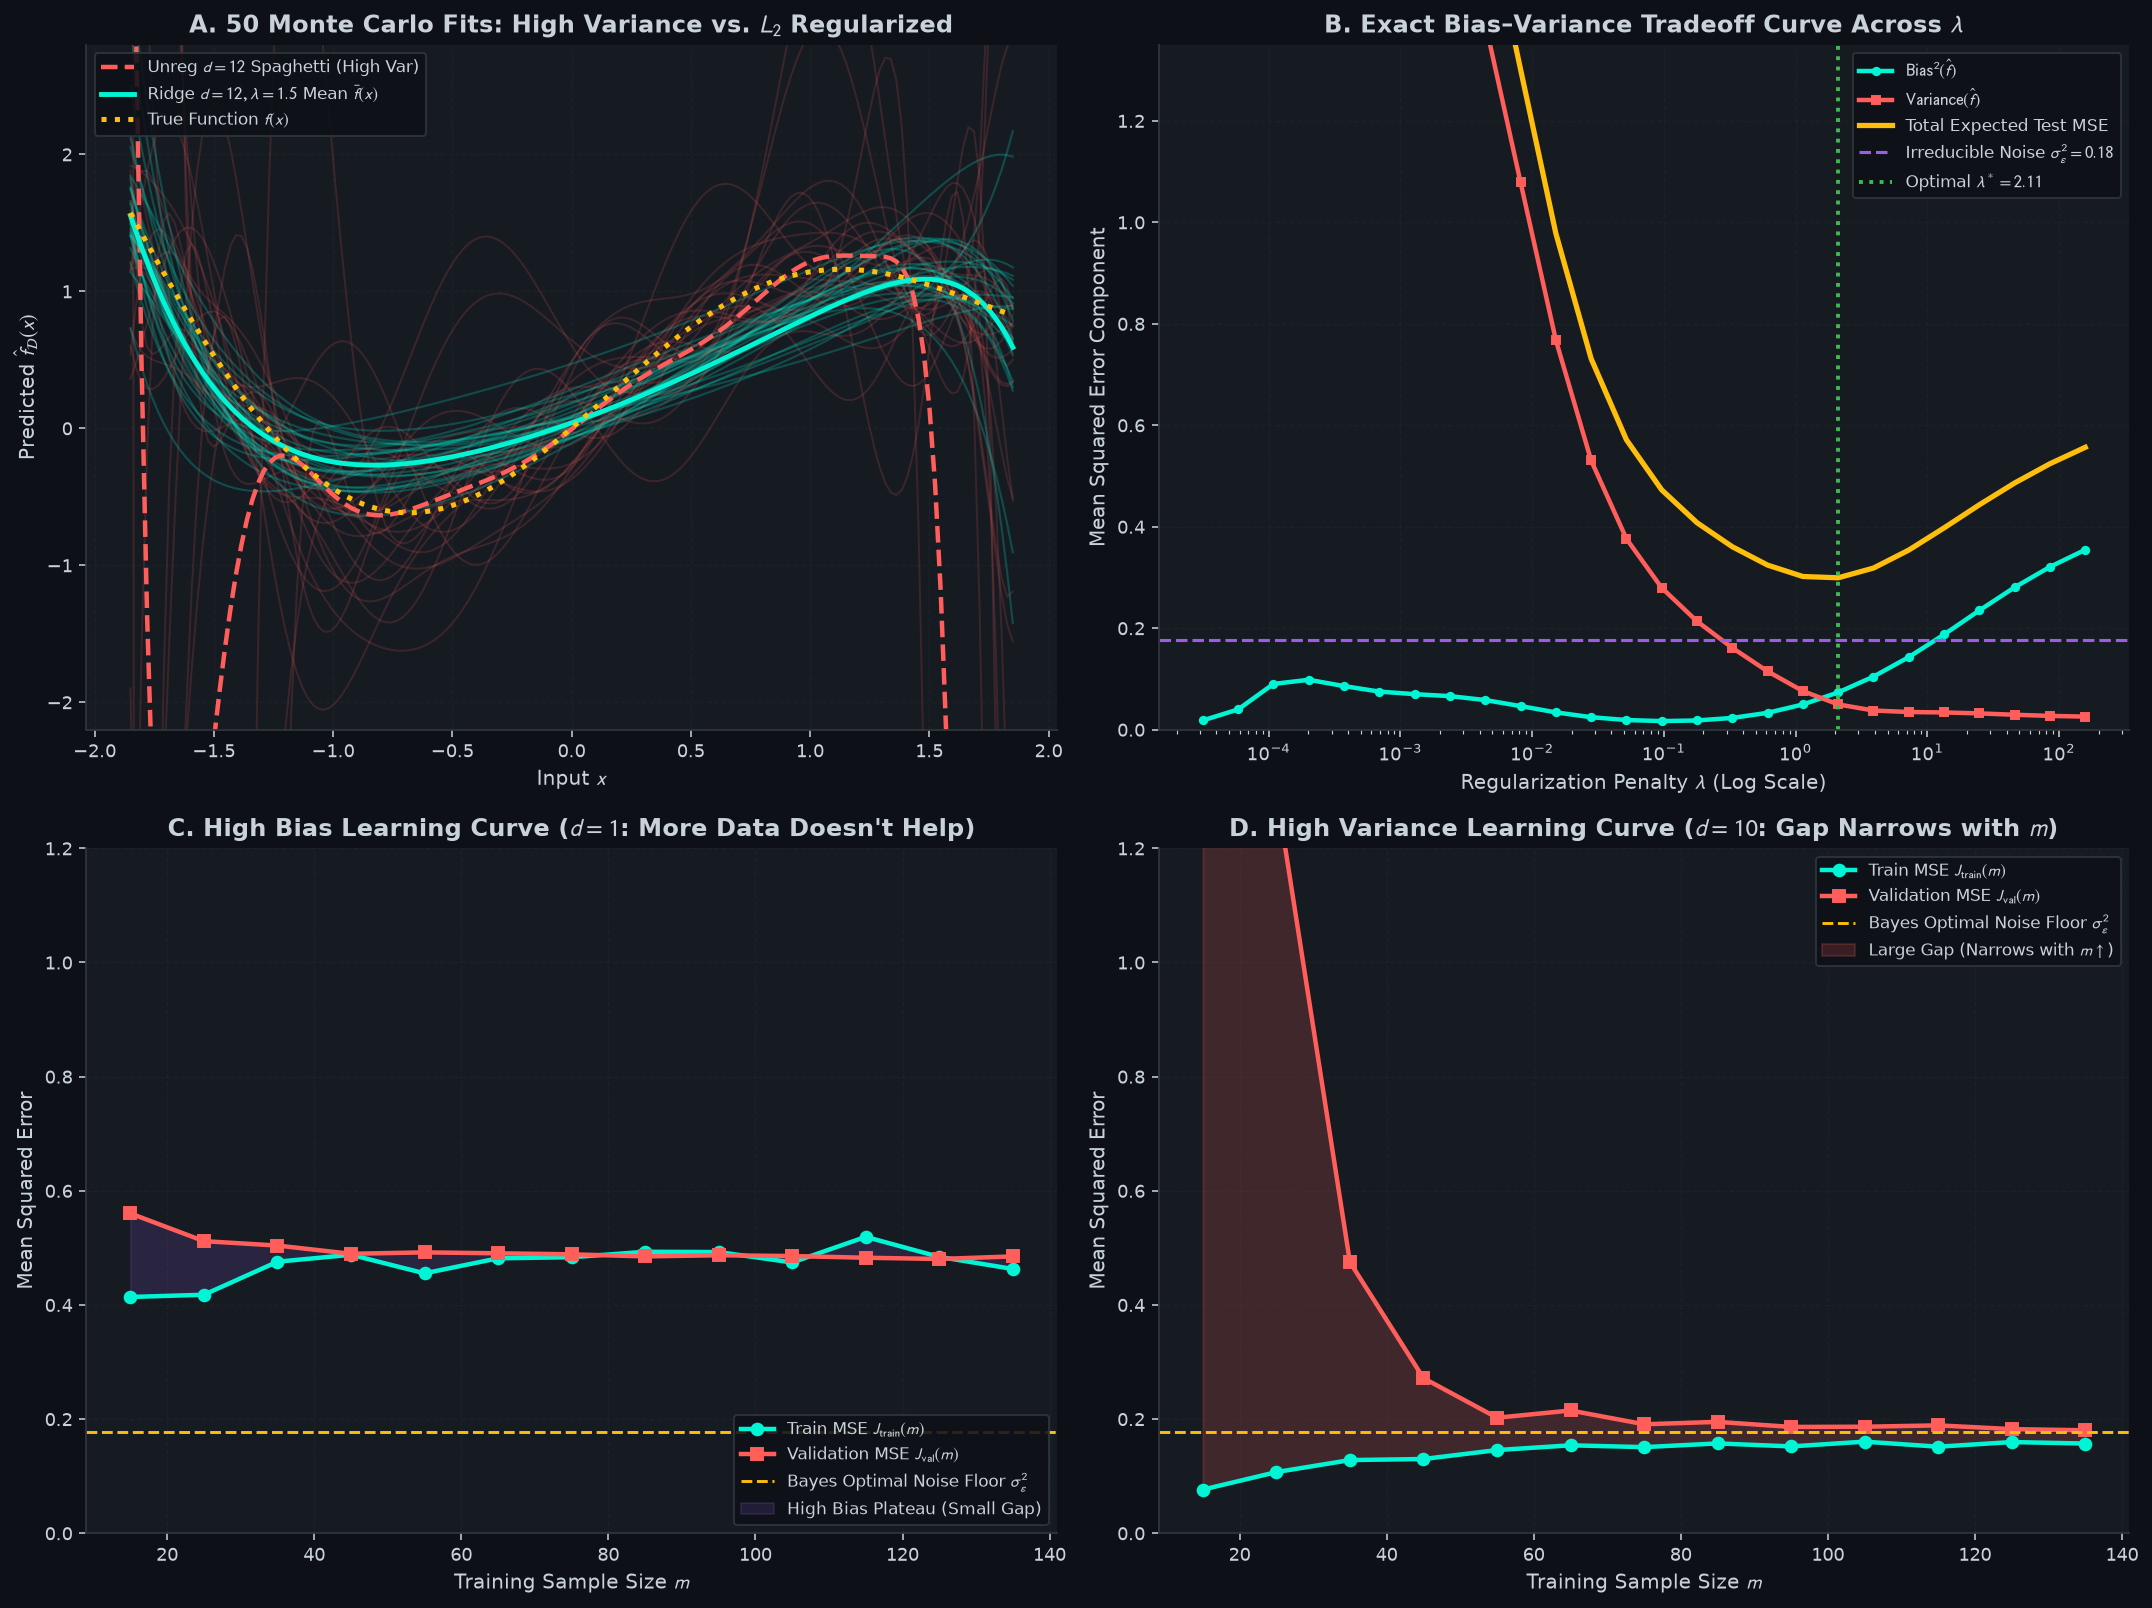

In [3]:
lambda_grid = np.logspace(-4.5, 2.2, 26)
bias_sq_curve, var_curve, total_curve = [], [], []

for lam in lambda_grid:
    stats = bias_variance_monte_carlo(
        make_poly_predictor(degree=12, l2_lambda=float(lam)),
        f_true,
        x_eval,
        n_trials=45,
        m_samples=26,
        noise_std=noise_sigma,
    )
    bias_sq_curve.append(stats["bias_sq"])
    var_curve.append(stats["variance"])
    total_curve.append(stats["total_mse"])

best_lam_idx = int(np.argmin(total_curve))
best_lam = float(lambda_grid[best_lam_idx])

# Sample-Size Learning Curves (m from 15 to 145)
sample_sizes = np.arange(15, 145, 10)
rng = np.random.default_rng(99)
X_val_fixed = np.linspace(-1.8, 1.8, 200).reshape(-1, 1)
y_val_fixed = f_true(X_val_fixed) + rng.normal(0.0, noise_sigma, size=(200, 1))

hb_train, hb_val = [], []
hv_train, hv_val = [], []

for m_sz in sample_sizes:
    tr_b_trials, va_b_trials = [], []
    tr_v_trials, va_v_trials = [], []
    for t in range(25):
        X_tr_m = rng.uniform(-1.85, 1.85, size=(int(m_sz), 1))
        y_tr_m = f_true(X_tr_m) + rng.normal(0.0, noise_sigma, size=(int(m_sz), 1))

        # High Bias (Degree 1)
        fn_hb = make_poly_predictor(degree=1, l2_lambda=1e-4)
        tr_b_trials.append(np.mean((fn_hb(X_tr_m, y_tr_m, X_tr_m) - y_tr_m.ravel()) ** 2))
        va_b_trials.append(np.mean((fn_hb(X_tr_m, y_tr_m, X_val_fixed) - y_val_fixed.ravel()) ** 2))

        # High Variance (Degree 10, weak regularization)
        fn_hv = make_poly_predictor(degree=10, l2_lambda=1e-4)
        tr_v_trials.append(np.mean((fn_hv(X_tr_m, y_tr_m, X_tr_m) - y_tr_m.ravel()) ** 2))
        va_v_trials.append(np.mean((fn_hv(X_tr_m, y_tr_m, X_val_fixed) - y_val_fixed.ravel()) ** 2))

    hb_train.append(float(np.mean(tr_b_trials)))
    hb_val.append(float(np.mean(va_b_trials)))
    hv_train.append(float(np.mean(tr_v_trials)))
    hv_val.append(float(np.mean(va_v_trials)))

fig, axes = plt.subplots(2, 2, figsize=(15.5, 11.6))

# Panel A: 50 Monte Carlo Polynomial Fits
ax1 = axes[0, 0]
for i in range(25):
    ax1.plot(x_eval, mc_overfit["preds_matrix"][i], color=CORAL, alpha=0.16, linewidth=1.0)
    ax1.plot(x_eval, mc_regularized["preds_matrix"][i], color=CYAN, alpha=0.22, linewidth=1.1)

ax1.plot(x_eval, mc_overfit["f_bar"], color=CORAL, linewidth=2.3, linestyle="--", label="Unreg $d=12$ Spaghetti (High Var)")
ax1.plot(x_eval, mc_regularized["f_bar"], color=CYAN, linewidth=2.5, label=r"Ridge $d=12, \lambda=1.5$ Mean $\bar{f}(x)$")
ax1.plot(x_eval, mc_regularized["f_true"], color=AMBER, linewidth=2.6, linestyle=":", label="True Function $f(x)$")
ax1.set_ylim(-2.2, 2.8)
ax1.set_xlabel("Input $x$")
ax1.set_ylabel(r"Predicted $\hat{f}_{\mathcal{D}}(x)$")
ax1.set_title("A. 50 Monte Carlo Fits: High Variance vs. $L_2$ Regularized")
ax1.legend(loc="upper left", fontsize=8.5)

# Panel B: Exact Bias^2 + Variance + Noise Decomposition
ax2 = axes[0, 1]
ax2.semilogx(lambda_grid, bias_sq_curve, color=CYAN, linewidth=2.3, marker="o", markersize=3.8, label=r"$\mathrm{Bias}^2(\hat{f})$")
ax2.semilogx(lambda_grid, var_curve, color=CORAL, linewidth=2.3, marker="s", markersize=3.8, label=r"$\mathrm{Variance}(\hat{f})$")
ax2.semilogx(lambda_grid, total_curve, color=AMBER, linewidth=2.7, label=r"Total Expected Test MSE")
ax2.axhline(noise_sigma ** 2, color=PURPLE, linestyle="--", linewidth=1.6, label=rf"Irreducible Noise $\sigma_\epsilon^2 = {noise_sigma**2:.2f}$")
ax2.axvline(best_lam, color=EMERALD, linestyle=":", linewidth=2.0, label=rf"Optimal $\lambda^* = {best_lam:.2f}$")
ax2.set_ylim(0.0, 1.35)
ax2.set_xlabel(r"Regularization Penalty $\lambda$ (Log Scale)")
ax2.set_ylabel("Mean Squared Error Component")
ax2.set_title(r"B. Exact Bias–Variance Tradeoff Curve Across $\lambda$")
ax2.legend(loc="upper right", fontsize=8.5)

# Panel C: High Bias Learning Curve (d=1)
ax3 = axes[1, 0]
ax3.plot(sample_sizes, hb_train, color=CYAN, marker="o", linewidth=2.3, label=r"Train MSE $J_{\mathrm{train}}(m)$")
ax3.plot(sample_sizes, hb_val, color=CORAL, marker="s", linewidth=2.3, label=r"Validation MSE $J_{\mathrm{val}}(m)$")
ax3.axhline(noise_sigma ** 2, color=AMBER, linestyle="--", linewidth=1.5, label=r"Bayes Optimal Noise Floor $\sigma_\epsilon^2$")
ax3.fill_between(sample_sizes, hb_train, hb_val, color=PURPLE, alpha=0.15, label="High Bias Plateau (Small Gap)")
ax3.set_ylim(0.0, 1.2)
ax3.set_xlabel("Training Sample Size $m$")
ax3.set_ylabel("Mean Squared Error")
ax3.set_title(r"C. High Bias Learning Curve ($d=1$: More Data Doesn't Help)")
ax3.legend(loc="lower right", fontsize=8.5)

# Panel D: High Variance Learning Curve (d=10)
ax4 = axes[1, 1]
ax4.plot(sample_sizes, hv_train, color=CYAN, marker="o", linewidth=2.3, label=r"Train MSE $J_{\mathrm{train}}(m)$")
ax4.plot(sample_sizes, np.clip(hv_val, 0, 1.3), color=CORAL, marker="s", linewidth=2.3, label=r"Validation MSE $J_{\mathrm{val}}(m)$")
ax4.axhline(noise_sigma ** 2, color=AMBER, linestyle="--", linewidth=1.5, label=r"Bayes Optimal Noise Floor $\sigma_\epsilon^2$")
ax4.fill_between(sample_sizes, hv_train, np.clip(hv_val, 0, 1.3), color=CORAL, alpha=0.18, label=r"Large Gap (Narrows with $m \uparrow$)")
ax4.set_ylim(0.0, 1.2)
ax4.set_xlabel("Training Sample Size $m$")
ax4.set_ylabel("Mean Squared Error")
ax4.set_title(r"D. High Variance Learning Curve ($d=10$: Gap Narrows with $m$)")
ax4.legend(loc="upper right", fontsize=8.5)

fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "01_bias_variance_learning_curves.png")
plt.show()